## Imports

In [2]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import importlib
from pricing.blackscholes import *
from pricing.montecarlo import *



In [ ]:
# When reloading
import pricing.blackscholes
importlib.reload(pricing.blackscholes)

<module 'pricing.blackscholes' from 'C:\\Users\\xprp2\\Documents\\python\\derivatives-research\\src\\pricing\\blackscholes.py'>

## Greeks spot price dependence

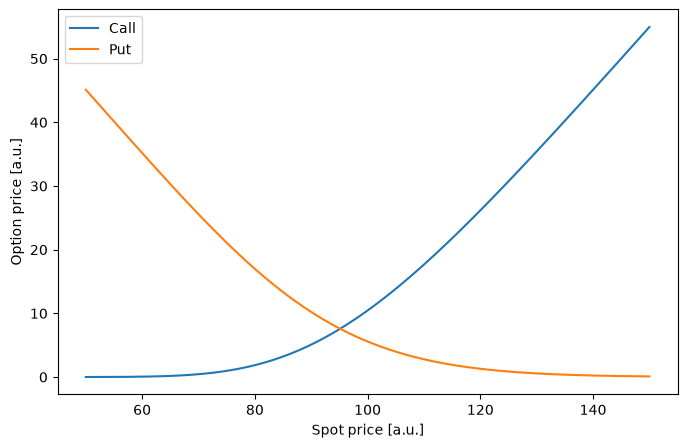

In [ ]:
S0_values = np.linspace(50, 150, 200)

# prices
K = 100
rate = 0.05
sigma = 0.20
T = 1.0

call_prices = [european_call_price(S0, K, rate, sigma, T) for S0 in S0_values]
put_prices = [european_put_price(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, call_prices, label="Call")
plt.plot(S0_values, put_prices, label="Put")
plt.xlabel("Spot price [a.u.]")
plt.ylabel("Option price [a.u.]")
plt.legend()
plt.show()

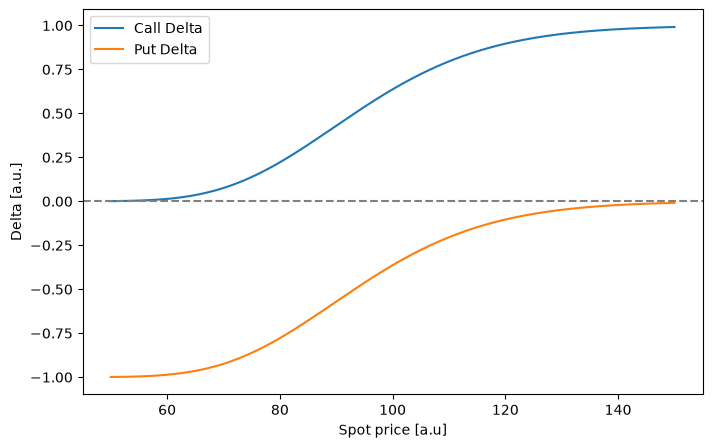

In [ ]:
# Delta
call_deltas = [call_delta(S0, K, rate, sigma, T) for S0 in S0_values]

put_deltas = [put_delta(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, call_deltas, label="Call delta")
plt.plot(S0_values, put_deltas, label="Put delta")
plt.xlabel("Spot price [a.u]")
plt.ylabel("Delta [a.u.]")
plt.axhline(y=0, linestyle="--", c='gray', )
plt.legend()
plt.show()

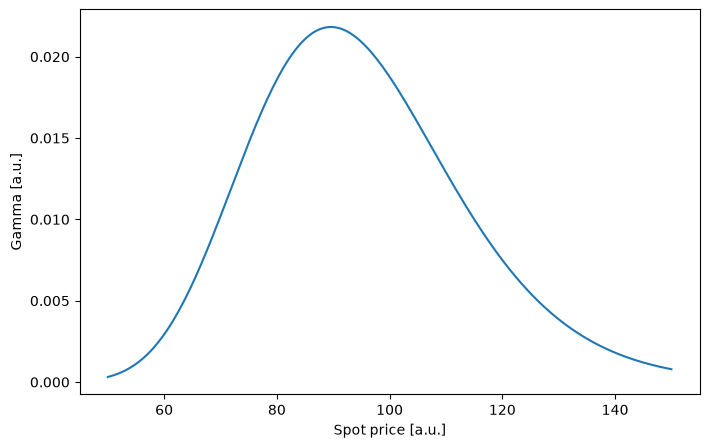

In [ ]:
# Gamma
gamma_values = [gamma(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, gamma_values)
plt.xlabel("Spot price [a.u.]")
plt.ylabel("Gamma [a.u.]")
plt.show()

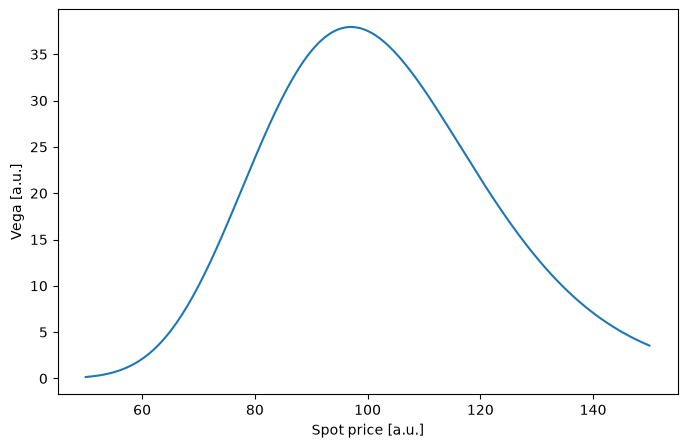

In [11]:
# Vega
vega_values = [vega(S0, K, rate, sigma, T) for S0 in S0_values]

plt.figure(figsize=(8, 5))
plt.plot(S0_values, vega_values)
plt.xlabel("Spot price [a.u.]")
plt.ylabel("Vega [a.u.]")
plt.show()

## Implied volatility with smile

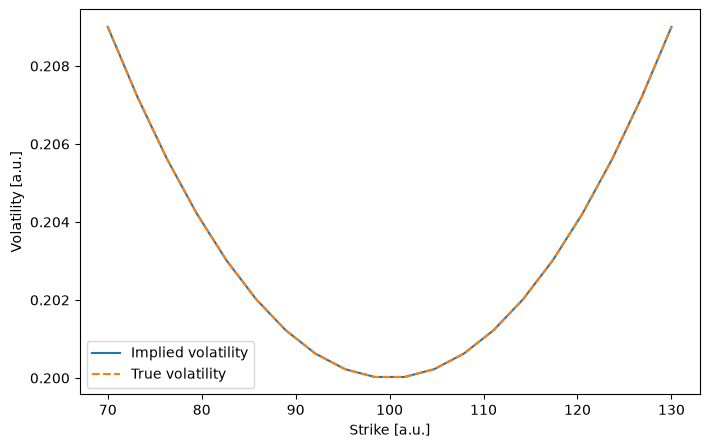

In [22]:
def volatility_smile(K):
    moneyness = K / 100
    return 0.20 + 0.10 * (moneyness - 1.0) ** 2

strike_prices = np.linspace(70, 130, 20)
true_sigma = 0.20

market_vols = [volatility_smile(K) for K in strike_prices]
market_prices = [european_call_price(S0=100, K=K, rate=0.05, sigma=sigma, T=1.0) for K, sigma in zip(strike_prices, market_vols)]
recovered_vols = [implied_volatility(market_price=price, S0=100, K=K,rate=0.05,T=1.0) for K, price in zip(strike_prices, market_prices)]

plt.figure(figsize=(8, 5))
plt.plot(strike_prices, recovered_vols, label="Implied volatility")
plt.plot(strike_prices, market_vols, linestyle="--", label="True volatility")

plt.xlabel("Strike [a.u.]")
plt.ylabel("Volatility [a.u.]")
plt.legend()
plt.show()

## Convergence of monte carlo

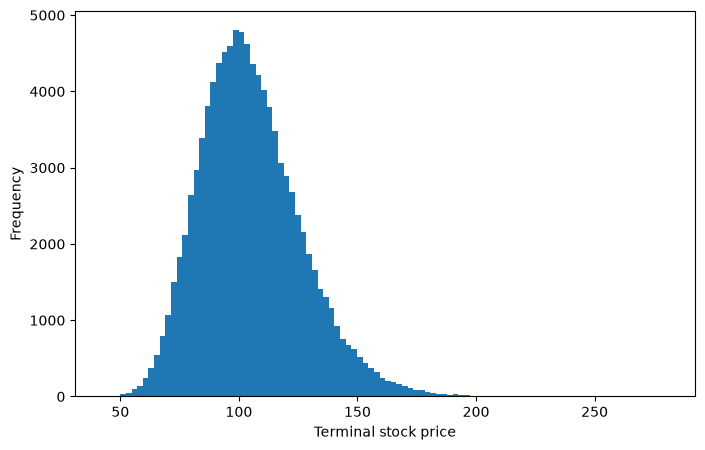

In [4]:
# Simulations of the stock at maturity
S0 = 100
K = 100
rate = 0.05
sigma = 0.20
T = 1.0

S_T = simulate_maturity_prices(S0, rate, sigma, T, n_paths=100_000, seed=42)

plt.figure(figsize=(8, 5))
plt.hist(S_T, bins=100)
plt.xlabel("Terminal stock price")
plt.ylabel("Frequency")
plt.show()

Black-Scholes price: 10.4506
Monte Carlo price:   10.5018
Monte Carlo error:   0.0468


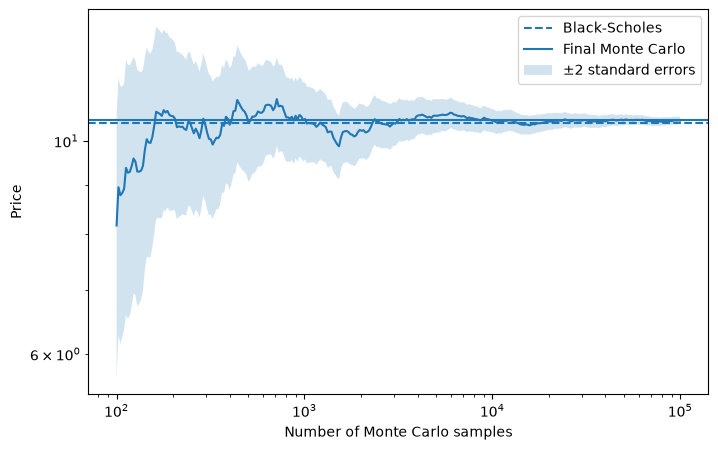

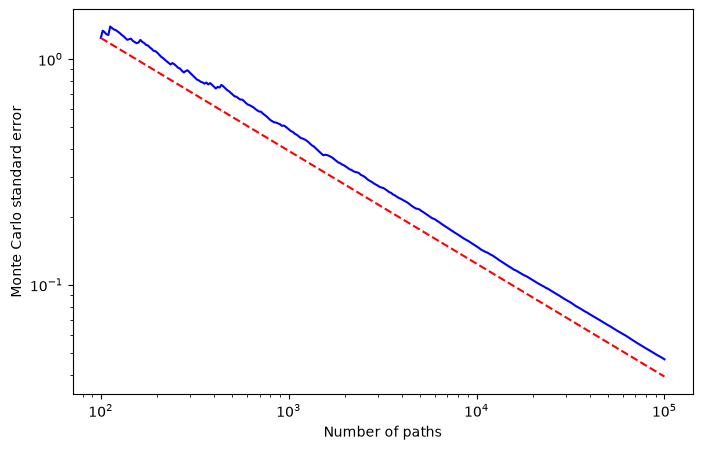

In [ ]:
# Convergence of monte carlo
mc_price_lst, mc_error_lst = [], []
n_paths_lst = np.logspace(2, 5, 300)

bs_price = european_call_price(S0, K, rate, sigma, T)

for n in n_paths_lst:
    mc_price, mc_error = price_european_call_mc(S0, K, rate, sigma, T, n_paths=int(n), seed=45)
    mc_price_lst.append(mc_price)
    mc_error_lst.append(mc_error)

print(f"Black-Scholes price: {bs_price:.4f}")
print(f"Monte Carlo price:   {mc_price:.4f}")
print(f"Monte Carlo error:   {mc_error:.4f}")

plt.figure(figsize=(8, 5))
plt.axhline(bs_price, linestyle="--", label="Black-Scholes")
plt.axhline(mc_price, label="Final Monte Carlo")
plt.plot(n_paths_lst, mc_price_lst)
plt.xscale("log")
plt.yscale("log")

plt.fill_between(n_paths_lst, np.array(mc_price_lst) - 2 * np.array(mc_error_lst), np.array(mc_price_lst) + 2 * np.array(mc_error_lst), alpha=0.2, label=r"$\pm 2$ standard errors")

plt.xlabel("Number of Monte Carlo samples")
plt.ylabel("Price")
plt.legend()
plt.show()

# Verifying 1/sqrt(N) behaviour
n_paths_lst = np.array(n_paths_lst)
reference = mc_error_lst[0] * np.sqrt(n_paths_lst[0] / n_paths_lst)
plt.figure(figsize=(8, 5))
plt.plot(n_paths_lst, mc_error_lst, color='blue', linestyle='-')
plt.plot(n_paths_lst, reference, color='red', linestyle="--")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of paths")
plt.ylabel("Monte Carlo standard error")
plt.show()


Monte Carlo is able to converge to the Black-Scholes price and the standard error follows the expected 1/sqrt(N) behaviour.